# Ejemplo práctico de una red neuronal construida a mano
---

Autor: Jorge Villacastín Blázquez

# 0 - Instalaciones necesarias e importación de librerías utilizadas

## Instalación de librerías

In [1]:
!pip install keras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 30.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 25.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.8/566.8 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 408.2/408.2 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.7/310.7 kB 26.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.7/91.7 kB 10.5 MB/s eta 0:00:00

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
!pip install tensorflow

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.4/223.4 MB 30.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 34.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 37.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 31.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.9/71.9 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 456.0/456.0 kB 32.4 MB/s eta 0:00:00
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.5/105.5 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 370.6/370.6 kB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69

In [4]:
!pip install scikit-image

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 32.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 328.1/328.1 kB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 30.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.0/244.0 kB 17.5 MB/s eta 0:00:00

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


## Importación de librerías

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from keras.datasets import mnist

from skimage import measure
import math

# 1 - Definición de funciones

In [14]:
### Sigmoid
def sigmoid(z):
    """
    Compute the sigmoid of z

    Arguments:
    x -- A scalar or numpy array of any size.

    Return:
    s -- sigmoid(z)
    """

    s=1/(1+np.exp(-z))
    
    return s

In [8]:
"""### Initialize weights"""

def initialize_weights(dim):
    """
    This function creates a vector of zeros of shape (dim, 1) for w and initializes b to 0.
    
    Argument:
    dim -- size of the w vector we want (or number of parameters in this case)
    
    Returns:
    w -- initialized vector of shape (dim, 1)
    b -- initialized scalar (corresponds to the bias)
    """

    w=np.zeros([dim,1])
    b=0
  
    assert(w.shape == (dim, 1))
    assert(isinstance(b, float) or isinstance(b, int))
    
    return w, b

In [11]:
"""### Forward and backward propagation"""

def propagate(w, b, X, Y):
    """
    Implement the cost function and its gradient for the propagation explained in the assignment

    Arguments:
    w -- weights, a numpy array of size (num_px * num_px, 1)
    b -- bias, a scalar
    X -- data of size (number of examples, num_px * num_px)
    Y -- true "label" vector of size (1, number of examples)

    Return:
    cost -- negative log-likelihood cost for logistic regression
    dw -- gradient of the loss with respect to w, thus same shape as w
    db -- gradient of the loss with respect to b, thus same shape as b
    
    """
    
    m = X.shape[0]
    
    # FORWARD PROPAGATION (FROM X TO COST)
   
    Y_hat=sigmoid(np.dot(w.T,X.T)+b)
    cost=np.sum(np.dot(np.log(Y_hat),Y.T)+np.dot(np.log(1-Y_hat),(1-Y.T)))
    cost=-(1/m)*cost
    
    # BACKWARD PROPAGATION (TO FIND GRAD)
   
    dw=np.dot(X.T,(Y_hat-Y).T)/m
    db=np.sum((Y_hat-Y))/m

    assert(dw.shape == w.shape)
    assert(db.dtype == float)
    cost = np.squeeze(cost)
    assert(cost.shape == ())
    
    grads = {"dw": dw,
             "db": db}
    
    return grads, cost

In [13]:
"""### Gradient descent"""

def gradient_descent(w, b, X, Y, num_iterations, learning_rate):
    """
    This function optimizes w and b by running a gradient descent algorithm
    
    Arguments:
    w -- weights, a numpy array of size (num_px * num_px, 1)
    b -- bias, a scalar
    X -- data of shape (num_px * num_px, number of examples)
    Y -- true "label" vector of shape (1, number of examples)
    num_iterations -- number of iterations of the optimization loop
    learning_rate -- learning rate of the gradient descent update rule
    
    Returns:
    params -- dictionary containing the weights w and bias b
    grads -- dictionary containing the gradients of the weights and bias with respect to the cost function
    costs -- list of all the costs computed during the optimization, this will be used to plot the learning curve.
    
    Tips:
    You basically need to write down two steps and iterate through them:
        1) Calculate the cost and the gradient for the current parameters. Use propagate().
        2) Update the parameters using gradient descent rule for w and b.
    """
    
    costs = []
    
    for i in range(num_iterations):
        
        
        # Cost and gradient calculation
      
        grads, cost = propagate(w, b, X, Y)
      
        # Retrieve derivatives from grads
        dw = grads["dw"]
        db = grads["db"]
        
        # update rule
        
        w=w-(learning_rate*dw)
        b=b-(learning_rate*db)

        # Record the costs
        if i % 100 == 0:
            costs.append(cost)
            # Print the cost every 100 training examples
            print ("Cost after iteration %i: %f" % (i, cost))
    
    params = {"w": w,
              "b": b}
    
    grads = {"dw": dw,
             "db": db}
    
    return params, grads, costs

In [16]:
"""### Make predictions"""

def predict(w, b, X):
    '''
    Predict whether the label is 0 or 1 using learned logistic regression parameters (w, b)
    
    Arguments:
    w -- weights, a numpy array of size (num_px * num_px, 1)
    b -- bias, a scalar
    X -- data of size (num_px * num_px, number of examples)
    
    Returns:
    Y_prediction -- a numpy array (vector) containing all predictions (0/1) for the examples in X
    '''
    
    m = X.shape[0]
    Y_prediction = np.zeros((1, m))
    w = w.reshape(X.shape[1], 1)
    
    # Compute vector "A" predicting the probabilities of the picture containing a 1
    
    A = sigmoid(np.dot(w.T, X.T) + b)
    
    
    for i in range(A.shape[1]):
        # Convert probabilities A[0,i] to actual predictions p[0,i]
        if A[0][i]>=0.5:
          Y_prediction[0][i]=1
        else:
          Y_prediction[0][i]=0


    
    assert(Y_prediction.shape == (1, m))
    
    return Y_prediction

In [17]:
"""#Metrics calculators"""

def TP_calculator(y,y_hat):
  TP=0
  for i in range(np.size(y)):
    if y[i]==0 and y_hat[i]==0:
      TP=TP+1
  return TP

def TN_calculator(y,y_hat):
  TN=0
  for i in range(np.size(y)):
    if y[i]==1 and y_hat[i]==1:
      TN=TN+1
  return TN

def FN_calculator(y,y_hat):
  FN=0
  for i in range(np.size(y)):
    if y[i]==0 and y_hat[i]==1:
      FN=FN+1
  return FN

def FP_calculator(y,y_hat):
  FP=0
  for i in range(np.size(y)):
    if y[i]==1 and y_hat[i]==0:
      FP=FP+1
  return FP

In [18]:
def plot_random_examples(x_data, y_data, num_examples=9):
    # Select random indices
    idx = np.random.choice(len(x_data), num_examples, replace=False)
    selected_images = x_data[idx]
    selected_labels = y_data[idx]

    # Create a 3x3 grid plot
    fig, axes = plt.subplots(3, 3, figsize=(6,6))
    axes = axes.flatten()

    for img, label, ax in zip(selected_images, selected_labels, axes):
        ax.imshow(img, cmap='gray')
        ax.set_title(f"Label: {label}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# 2 - Carga de datos y preparación para el entrenamiento - Números 0 y 1

In [19]:
# LOAD DATA
class0 = 0
class1 = 1

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train[np.isin(y_train,[class0,class1]),:,:]
y_train = 1*(y_train[np.isin(y_train,[class0,class1])]>class0)
x_test = x_test[np.isin(y_test,[class0,class1]),:,:]
y_test = 1*(y_test[np.isin(y_test,[class0,class1])]>class0)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


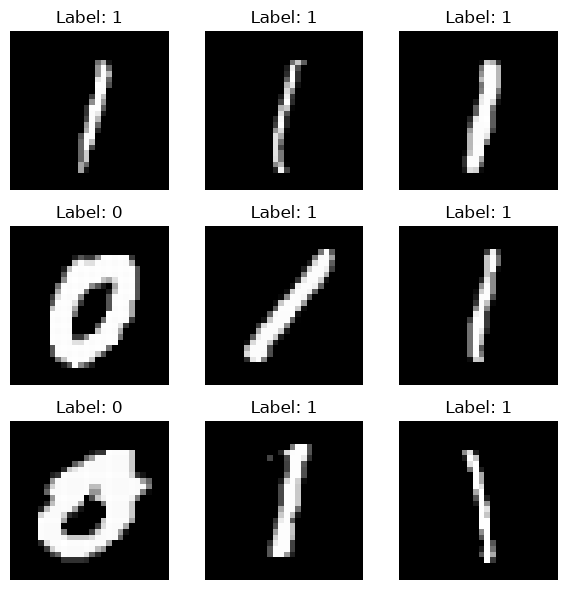

In [20]:
# Plot some examples
plot_random_examples(x_train, y_train)

In [21]:
np.shape(x_train[0])

(28, 28)

In [29]:
# RESHAPE

x_train_flat = x_train.reshape(x_train.shape[0],-1)
print(x_train_flat.shape)
print('Train: '+str(x_train_flat.shape[0])+' images and '+str(x_train_flat.shape[1])+' neurons \n')

x_test_flat = x_test.reshape(x_test.shape[0],-1)
print(x_test_flat.shape)
print('Test: '+str(x_test_flat.shape[0])+' images and '+str(x_test_flat.shape[1])+' neurons \n')

# STRANDARIZE
x_train_flat = x_train_flat / 255
x_test_flat = x_test_flat / 255

(12665, 784)
Train: 12665 images and 784 neurons 

(2115, 784)
Test: 2115 images and 784 neurons 



# 3 - Entrenamiento del modelo

In [24]:
"""### Train the model (in training set)"""

# Initialize parameters with zeros (≈ 1 line of code)
w, b = initialize_weights(x_train_flat.shape[1])

In [30]:
# Gradient descent (≈ 1 line of code)
learning_rate = 0.005
num_iterations = 3000
parameters, grads, costs = gradient_descent(w, b, x_train_flat, y_train, 3000, 0.005)

Cost after iteration 0: 0.693147
Cost after iteration 100: 0.201280
Cost after iteration 200: 0.120349
Cost after iteration 300: 0.088112
Cost after iteration 400: 0.070691
Cost after iteration 500: 0.059708
Cost after iteration 600: 0.052112
Cost after iteration 700: 0.046521
Cost after iteration 800: 0.042221
Cost after iteration 900: 0.038801
Cost after iteration 1000: 0.036010
Cost after iteration 1100: 0.033685
Cost after iteration 1200: 0.031714
Cost after iteration 1300: 0.030021
Cost after iteration 1400: 0.028548
Cost after iteration 1500: 0.027255
Cost after iteration 1600: 0.026108
Cost after iteration 1700: 0.025083
Cost after iteration 1800: 0.024162
Cost after iteration 1900: 0.023329
Cost after iteration 2000: 0.022570
Cost after iteration 2100: 0.021877
Cost after iteration 2200: 0.021240
Cost after iteration 2300: 0.020654
Cost after iteration 2400: 0.020111
Cost after iteration 2500: 0.019607
Cost after iteration 2600: 0.019137
Cost after iteration 2700: 0.018699
Cost

In [31]:
parameters['w']

array([[ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.00000000e+00],
       [ 0.0

In [32]:
parameters['b']

np.float64(0.1376402463989071)

In [33]:
grads

{'dw': array([[ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+00],
        [ 0.00000000e+

In [34]:
costs

[np.float64(0.6931471805599451),
 np.float64(0.20127959631732656),
 np.float64(0.1203489246512999),
 np.float64(0.08811207275205082),
 np.float64(0.07069072137392683),
 np.float64(0.059708204562185424),
 np.float64(0.05211168795039361),
 np.float64(0.04652129060935593),
 np.float64(0.04222083221953536),
 np.float64(0.03880084425869312),
 np.float64(0.03600982289832618),
 np.float64(0.0336845065187646),
 np.float64(0.03171414864635421),
 np.float64(0.030020883664436844),
 np.float64(0.028548309176498587),
 np.float64(0.027254529466986907),
 np.float64(0.02610774767243499),
 np.float64(0.025083378047635264),
 np.float64(0.02416209881159748),
 np.float64(0.023328505821284134),
 np.float64(0.022570160882519147),
 np.float64(0.021876905713593724),
 np.float64(0.02124035868241098),
 np.float64(0.02065353977622809),
 np.float64(0.020110587135045033),
 np.float64(0.019606540014662784),
 np.float64(0.019137170647551778),
 np.float64(0.018698852575814648),
 np.float64(0.01828845652007316),
 np.f

# 4 - Validación del modelo


train accuracy: 99.75523095144098 %
test accuracy: 99.90543735224587 %

Accuracy for testing data:
 0.9990543735224586
Sensitivity for testing data:
 0.9979591836734694
Specificity for testing data:
 1.0
Balanced accuracy for testing data:
 0.9989795918367347


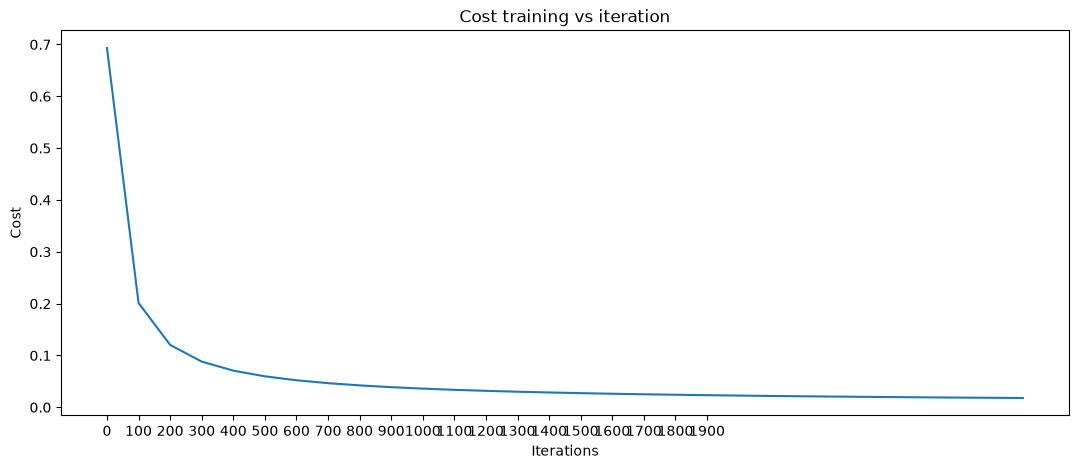

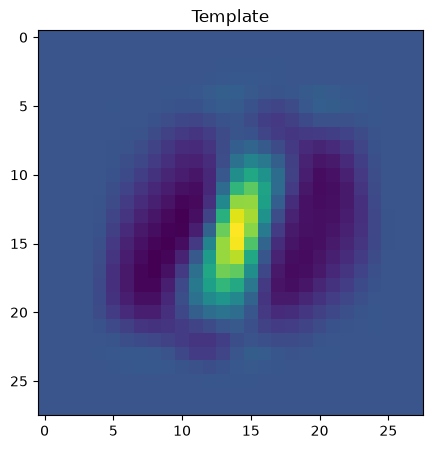

In [35]:
"""### Test the model (in testing set)"""

# Retrieve parameters w and b from dictionary "parameters"
w = parameters["w"]
b = parameters["b"]
    
# Predict test/train set examples (≈ 2 lines of code)
y_prediction_test = predict(w, b, x_test_flat)
y_prediction_train = predict(w, b, x_train_flat)

# Print train/test Errors
print('')
print("train accuracy: {} %".format(100 - np.mean(np.abs(y_prediction_train - y_train)) * 100))
print("test accuracy: {} %".format(100 - np.mean(np.abs(y_prediction_test - y_test)) * 100))
print('')

plt.figure(figsize=(13,5))
plt.plot(range(0,3000,100),costs)
plt.title('Cost training vs iteration')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.xticks(range(0,2000,100))


plt.figure(figsize=(13,5))
plt.imshow(w.reshape(28,28))
plt.title('Template')

TP=TP_calculator(y_test,np.squeeze(y_prediction_test))
TN=TN_calculator(y_test,np.squeeze(y_prediction_test))
FP=FP_calculator(y_test,np.squeeze(y_prediction_test))
FN=FN_calculator(y_test,np.squeeze(y_prediction_test))

AccTest=(TP+TN)/(TP+TN+FN+FP)
print("Accuracy for testing data:\n", AccTest)
SensTest=TP/(TP+FN)
print("Sensitivity for testing data:\n", SensTest)
SpecTest=TN/(TN+FP)
print("Specificity for testing data:\n", SpecTest)
BalancedAccTest=(SensTest + SpecTest)/2
print("Balanced accuracy for testing data:\n", BalancedAccTest)

# 5 - Carga de datos y preparación para el entrenamiento - Números 5 y 6

In [36]:
"""## Merge functions and run your model now for 5 and 6"""

# LOAD DATA
class0 = 5
class1 = 6

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train[np.isin(y_train,[class0,class1]),:,:]
y_train = 1*(y_train[np.isin(y_train,[class0,class1])]>class0)
x_test = x_test[np.isin(y_test,[class0,class1]),:,:]
y_test = 1*(y_test[np.isin(y_test,[class0,class1])]>class0)

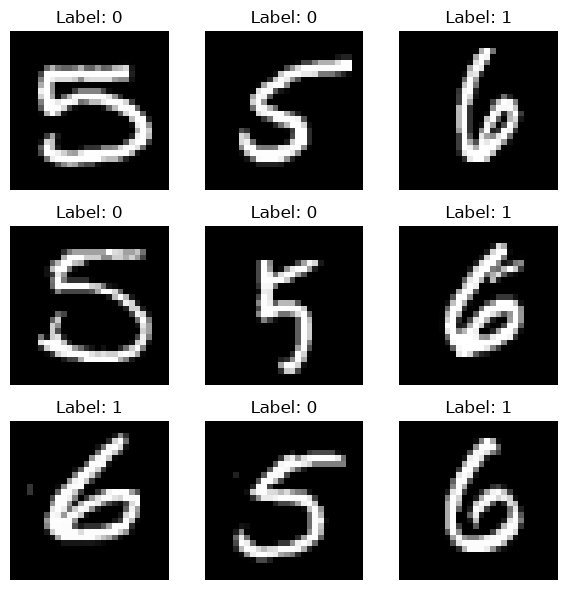

In [37]:
# Plot some examples
plot_random_examples(x_train, y_train)

In [38]:
# RESHAPE

x_train_flat = x_train.reshape(x_train.shape[0],-1)
print(x_train_flat.shape)
print('Train: '+str(x_train_flat.shape[0])+' images and '+str(x_train_flat.shape[1])+' neurons \n')

x_test_flat = x_test.reshape(x_test.shape[0],-1)
print(x_test_flat.shape)
print('Test: '+str(x_test_flat.shape[0])+' images and '+str(x_test_flat.shape[1])+' neurons \n')

# STRANDARIZE
x_train_flat = x_train_flat / 255
x_test_flat = x_test_flat / 255

(11339, 784)
Train: 11339 images and 784 neurons 

(1850, 784)
Test: 1850 images and 784 neurons 



# 6 - Entrenamiento del modelo

In [39]:
"""### Train the model (in training set)"""

# Initialize parameters with zeros (≈ 1 line of code)
w, b = initialize_weights(x_train_flat.shape[1])

# Gradient descent (≈ 1 line of code)
learning_rate = 0.01
num_iterations = 2000
parameters, grads, costs = gradient_descent(w, b, x_train_flat, y_train, num_iterations, learning_rate)

Cost after iteration 0: 0.693147
Cost after iteration 100: 0.288627
Cost after iteration 200: 0.211291
Cost after iteration 300: 0.177255
Cost after iteration 400: 0.157510
Cost after iteration 500: 0.144383
Cost after iteration 600: 0.134914
Cost after iteration 700: 0.127703
Cost after iteration 800: 0.121992
Cost after iteration 900: 0.117337
Cost after iteration 1000: 0.113453
Cost after iteration 1100: 0.110153
Cost after iteration 1200: 0.107306
Cost after iteration 1300: 0.104821
Cost after iteration 1400: 0.102626
Cost after iteration 1500: 0.100671
Cost after iteration 1600: 0.098915
Cost after iteration 1700: 0.097327
Cost after iteration 1800: 0.095882
Cost after iteration 1900: 0.094559


# 7 - Validación del modelo


train accuracy: 97.22197724667078 %
test accuracy: 97.72972972972973 %

Accuracy for testing data:
 0.9772972972972973
Sensitivity for testing data:
 0.9730941704035875
Specificity for testing data:
 0.9812108559498957
Balanced accuracy for testing data:
 0.9771525131767416


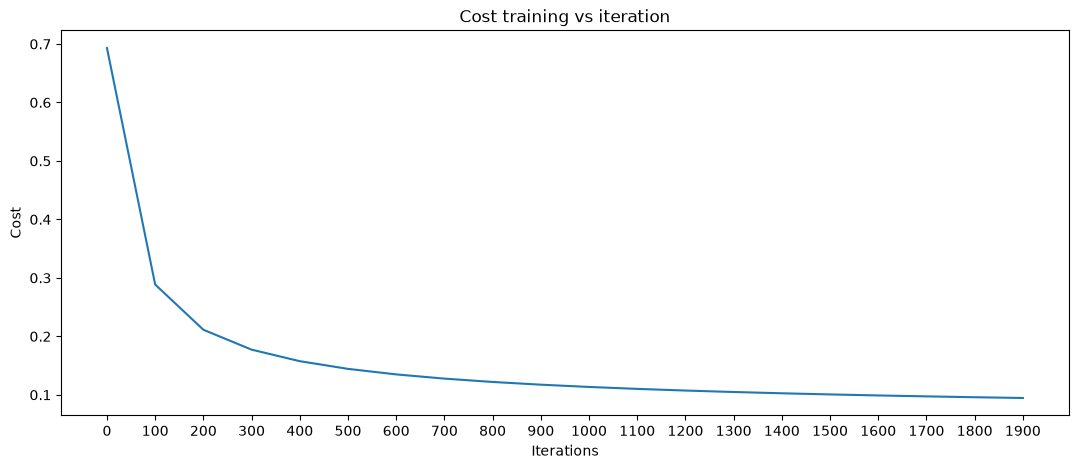

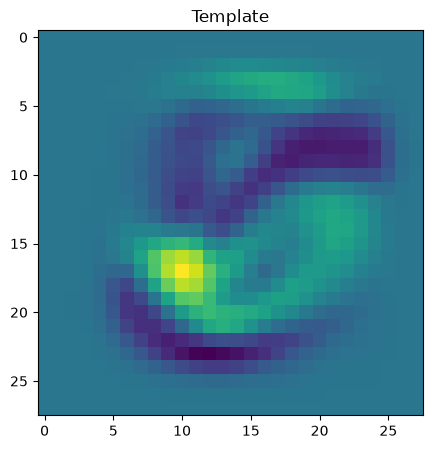

In [40]:
"""### Test the model (in testing set)"""

# Retrieve parameters w and b from dictionary "parameters"
w = parameters["w"]
b = parameters["b"]
    
# Predict test/train set examples (≈ 2 lines of code)
y_prediction_test = predict(w, b, x_test_flat)
y_prediction_train = predict(w, b, x_train_flat)

# Print train/test Errors
print('')
print("train accuracy: {} %".format(100 - np.mean(np.abs(y_prediction_train - y_train)) * 100))
print("test accuracy: {} %".format(100 - np.mean(np.abs(y_prediction_test - y_test)) * 100))
print('')

plt.figure(figsize=(13,5))
plt.plot(range(0,2000,100),costs)
plt.title('Cost training vs iteration')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.xticks(range(0,2000,100))


plt.figure(figsize=(13,5))
plt.imshow(w.reshape(28,28))
plt.title('Template')

TP=TP_calculator(y_test,np.squeeze(y_prediction_test))
TN=TN_calculator(y_test,np.squeeze(y_prediction_test))
FP=FP_calculator(y_test,np.squeeze(y_prediction_test))
FN=FN_calculator(y_test,np.squeeze(y_prediction_test))

AccTest=(TP+TN)/(TP+TN+FN+FP)
print("Accuracy for testing data:\n", AccTest)
SensTest=TP/(TP+FN)
print("Sensitivity for testing data:\n", SensTest)
SpecTest=TN/(TN+FP)
print("Specificity for testing data:\n", SpecTest)
BalancedAccTest=(SensTest + SpecTest)/2
print("Balanced accuracy for testing data:\n", BalancedAccTest)

# 5 - Carga de datos y preparación para el entrenamiento - Números 0 y 8

In [41]:
"""## Merge functions and run your model now for 5 and 6"""

# LOAD DATA
class0 = 0
class1 = 8

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train[np.isin(y_train,[class0,class1]),:,:]
y_train = 1*(y_train[np.isin(y_train,[class0,class1])]>class0)
x_test = x_test[np.isin(y_test,[class0,class1]),:,:]
y_test = 1*(y_test[np.isin(y_test,[class0,class1])]>class0)

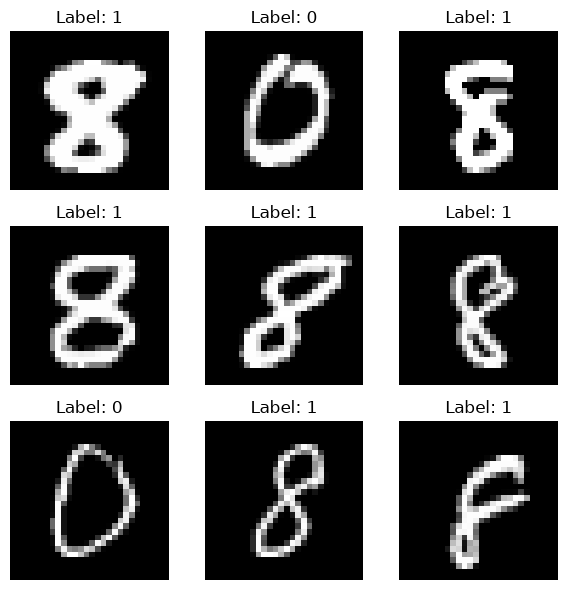

In [42]:
# Plot some examples
plot_random_examples(x_train, y_train)

In [43]:
# RESHAPE

x_train_flat = x_train.reshape(x_train.shape[0],-1)
print(x_train_flat.shape)
print('Train: '+str(x_train_flat.shape[0])+' images and '+str(x_train_flat.shape[1])+' neurons \n')

x_test_flat = x_test.reshape(x_test.shape[0],-1)
print(x_test_flat.shape)
print('Test: '+str(x_test_flat.shape[0])+' images and '+str(x_test_flat.shape[1])+' neurons \n')

# STRANDARIZE
x_train_flat = x_train_flat / 255
x_test_flat = x_test_flat / 255

(11774, 784)
Train: 11774 images and 784 neurons 

(1954, 784)
Test: 1954 images and 784 neurons 



# 6 - Entrenamiento del modelo

In [44]:
"""### Train the model (in training set)"""

# Initialize parameters with zeros (≈ 1 line of code)
w, b = initialize_weights(x_train_flat.shape[1])

# Gradient descent (≈ 1 line of code)
learning_rate = 1
num_iterations = 2000
parameters, grads, costs = gradient_descent(w, b, x_train_flat, y_train, num_iterations, learning_rate)

Cost after iteration 0: 0.693147
Cost after iteration 100: 0.029184
Cost after iteration 200: 0.025295
Cost after iteration 300: 0.023330
Cost after iteration 400: 0.022069
Cost after iteration 500: 0.021163
Cost after iteration 600: 0.020465
Cost after iteration 700: 0.019902
Cost after iteration 800: 0.019432
Cost after iteration 900: 0.019030
Cost after iteration 1000: 0.018678
Cost after iteration 1100: 0.018366
Cost after iteration 1200: 0.018087
Cost after iteration 1300: 0.017833
Cost after iteration 1400: 0.017600
Cost after iteration 1500: 0.017386
Cost after iteration 1600: 0.017187
Cost after iteration 1700: 0.017002
Cost after iteration 1800: 0.016828
Cost after iteration 1900: 0.016665


# 7 - Validación del modelo


train accuracy: 99.56684219466621 %
test accuracy: 99.33469805527123 %

Accuracy for testing data:
 0.9933469805527124
Sensitivity for testing data:
 0.996938775510204
Specificity for testing data:
 0.9897330595482546
Balanced accuracy for testing data:
 0.9933359175292293


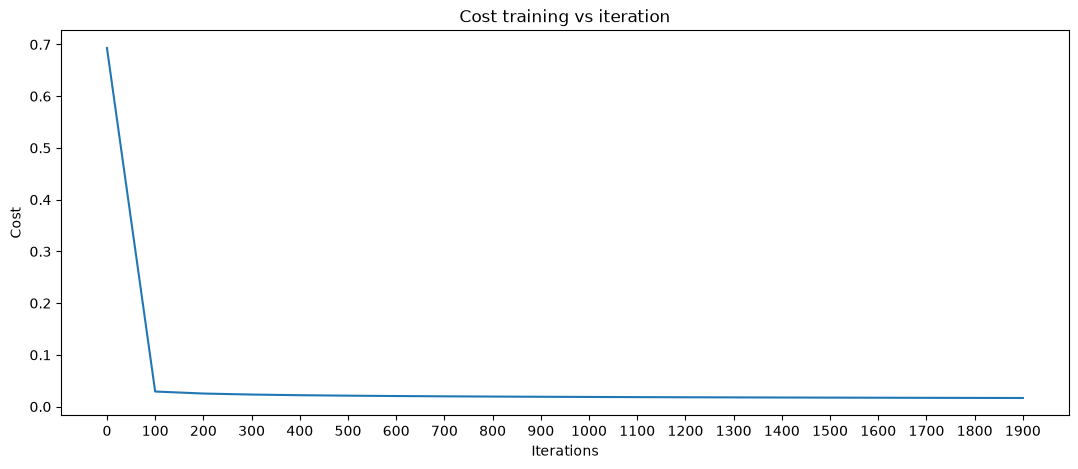

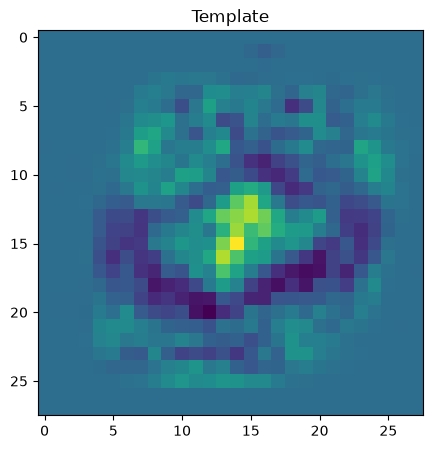

In [45]:
"""### Test the model (in testing set)"""

# Retrieve parameters w and b from dictionary "parameters"
w = parameters["w"]
b = parameters["b"]
    
# Predict test/train set examples (≈ 2 lines of code)
y_prediction_test = predict(w, b, x_test_flat)
y_prediction_train = predict(w, b, x_train_flat)

# Print train/test Errors
print('')
print("train accuracy: {} %".format(100 - np.mean(np.abs(y_prediction_train - y_train)) * 100))
print("test accuracy: {} %".format(100 - np.mean(np.abs(y_prediction_test - y_test)) * 100))
print('')

plt.figure(figsize=(13,5))
plt.plot(range(0,2000,100),costs)
plt.title('Cost training vs iteration')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.xticks(range(0,2000,100))


plt.figure(figsize=(13,5))
plt.imshow(w.reshape(28,28))
plt.title('Template')

TP=TP_calculator(y_test,np.squeeze(y_prediction_test))
TN=TN_calculator(y_test,np.squeeze(y_prediction_test))
FP=FP_calculator(y_test,np.squeeze(y_prediction_test))
FN=FN_calculator(y_test,np.squeeze(y_prediction_test))

AccTest=(TP+TN)/(TP+TN+FN+FP)
print("Accuracy for testing data:\n", AccTest)
SensTest=TP/(TP+FN)
print("Sensitivity for testing data:\n", SensTest)
SpecTest=TN/(TN+FP)
print("Specificity for testing data:\n", SpecTest)
BalancedAccTest=(SensTest + SpecTest)/2
print("Balanced accuracy for testing data:\n", BalancedAccTest)